# Final model summary: ResNeXt-29 (4x24d) student, 4,998,738 parameters

This notebook needs no GPU and no weights. It
1. builds the final architecture from `src/models.py` and prints the **number of trainable parameters** (with `torchsummary`),
2. prints the **final accuracies** saved by the evaluation cell of `notebooks/03_final_finetune_100ep.ipynb` (`results/.../results.json`), and the Kaggle scores,
3. plots the training curves of the teacher, the 400-epoch student and the final 100-epoch fine-tune from their `history.csv`.

The accuracies themselves were computed in notebook 03 (section 12) from `best.pt`; to recompute them, run that notebook with the checkpoint from Google Drive (see README).

In [1]:
import sys, json, os
sys.path.insert(0, "..")
import torch, pandas as pd, matplotlib.pyplot as plt
from torchsummary import summary
from src.models import build_model, count_params, FINAL_CFG

model = build_model(FINAL_CFG)
n = count_params(model)
print(f"Final model: ResNeXt-29, cardinality {FINAL_CFG['CARDINALITY']}, bottleneck width {FINAL_CFG['BOTTLENECK_WIDTH']}, "
      f"stage widths {FINAL_CFG['WIDTHS']}, blocks {FINAL_CFG['BLOCKS']}")
print(f"Trainable parameters (incl. the training-only SLA head): {n:,}  (limit 5,000,000)")
assert n <= 5_000_000
print(f"  of which SLA joint head (used only in training): {sum(p.numel() for p in model.fc_joint.parameters()):,}")
print(f"  inference network (stem + 9 blocks + 10-class head): {n - sum(p.numel() for p in model.fc_joint.parameters()):,}")

Final model: ResNeXt-29, cardinality 4, bottleneck width 24, stage widths (280, 528, 1040), blocks (3, 3, 3)
Trainable parameters (incl. the training-only SLA head): 4,998,738  (limit 5,000,000)
  of which SLA joint head (used only in training): 41,640
  inference network (stem + 9 blocks + 10-class head): 4,957,098


In [2]:
summary(model, (3, 32, 32), device="cpu")

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 32, 32]           1,728
       BatchNorm2d-2           [-1, 64, 32, 32]             128
              ReLU-3           [-1, 64, 32, 32]               0
            Conv2d-4           [-1, 96, 32, 32]           6,144
       BatchNorm2d-5           [-1, 96, 32, 32]             192
            Conv2d-6           [-1, 96, 32, 32]          20,736
       BatchNorm2d-7           [-1, 96, 32, 32]             192
            Conv2d-8          [-1, 280, 32, 32]          26,880
       BatchNorm2d-9          [-1, 280, 32, 32]             560
           Conv2d-10          [-1, 280, 32, 32]          17,920
      BatchNorm2d-11          [-1, 280, 32, 32]             560
     ResNeXtBlock-12          [-1, 280, 32, 32]               0
           Conv2d-13           [-1, 96, 32, 32]          26,880
      BatchNorm2d-14           [-1, 96,

In [3]:
R = "../results/kd_sewrn_only_student_resnext29_slasd_400ep_v1_ft100_lr0.02/results.json"
r = json.load(open(R))
print(f"run: {r['run']} | best epoch {r['best_epoch']} | params {r['n_params']:,}")
print(f"FINAL validation accuracy    (2,500 held-out train images): {r['val']['accuracy']:.4f}")
print(f"FINAL internal test accuracy (2,500 held-out train images): {r['internal_test']['accuracy']:.4f}")
print("FINAL Kaggle accuracy (2,000 hidden test images, CIFAR-10.2-style): public 0.912 | private 0.888")
pd.DataFrame(r["internal_test_per_class"]).round(4)

run: kd_sewrn_only_student_resnext29_slasd_400ep_v1_ft100_lr0.02 | best epoch 77 | params 4,998,738
FINAL validation accuracy    (2,500 held-out train images): 0.9880
FINAL internal test accuracy (2,500 held-out train images): 0.9828
FINAL Kaggle accuracy (2,000 hidden test images, CIFAR-10.2-style): public 0.912 | private 0.888


,recall,errors,mean p(true),mean NLL
airplane,0.988,3,0.9714,0.0503
automobile,0.984,4,0.9664,0.0563
bird,0.964,9,0.9540,0.0753
cat,0.972,7,0.9480,0.0742
deer,0.992,2,0.9722,0.0436
dog,0.968,8,0.9408,0.1041
frog,0.992,2,0.9789,0.0313
horse,0.972,7,0.9644,0.0707
ship,0.996,1,0.9847,0.0210
truck,1.000,0,0.9861,0.0155


teacher SE-WRN-28-10 + SLA (36.8M, training only)       best val 0.9880 (epoch 233)
student ResNeXt-29, KD 400 ep                           best val 0.9856 (epoch 390)
FINAL: student + 100 ep fine-tune                       best val 0.9856 (epoch 77)


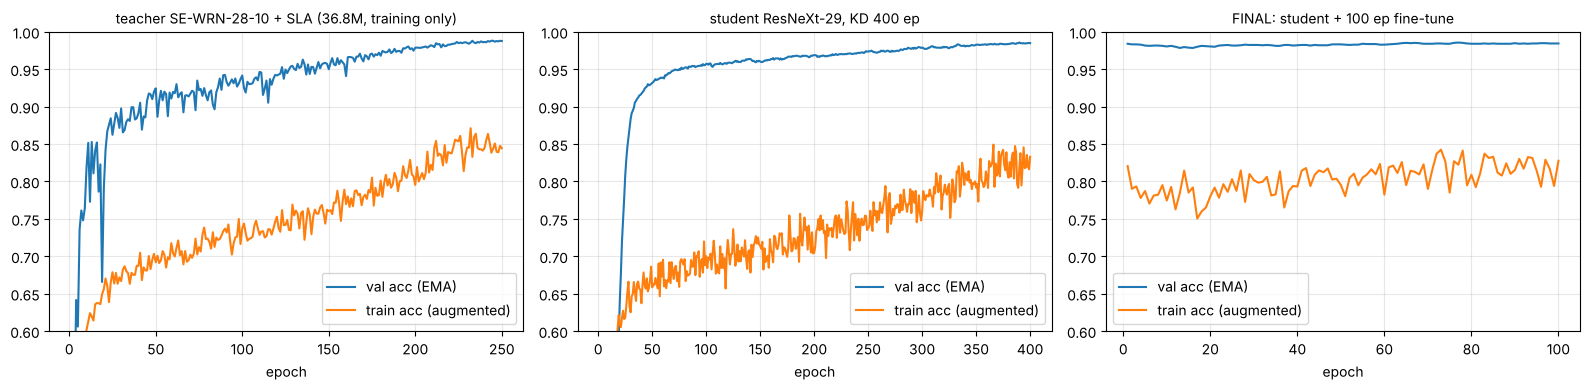

In [4]:
runs = {"teacher SE-WRN-28-10 + SLA (36.8M, training only)": "teacher_sewrn28_10_sla250_v1",
        "student ResNeXt-29, KD 400 ep": "kd_sewrn_only_student_resnext29_slasd_400ep_v1",
        "FINAL: student + 100 ep fine-tune": "kd_sewrn_only_student_resnext29_slasd_400ep_v1_ft100_lr0.02"}
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for i, (title, rn) in enumerate(runs.items()):
    h = pd.read_csv(f"../results/{rn}/history.csv")
    ax[i].plot(h["epoch"], h["val_acc"], label="val acc (EMA)")
    if "train_acc" in h: ax[i].plot(h["epoch"], h["train_acc"], label="train acc (augmented)")
    ax[i].set_title(title, fontsize=10); ax[i].set_xlabel("epoch"); ax[i].set_ylim(0.6, 1.0); ax[i].grid(alpha=.3); ax[i].legend()
    print(f"{title:55s} best val {h['val_acc'].max():.4f} (epoch {int(h.loc[h['val_acc'].idxmax(), 'epoch'])})")
plt.tight_layout(); plt.show()

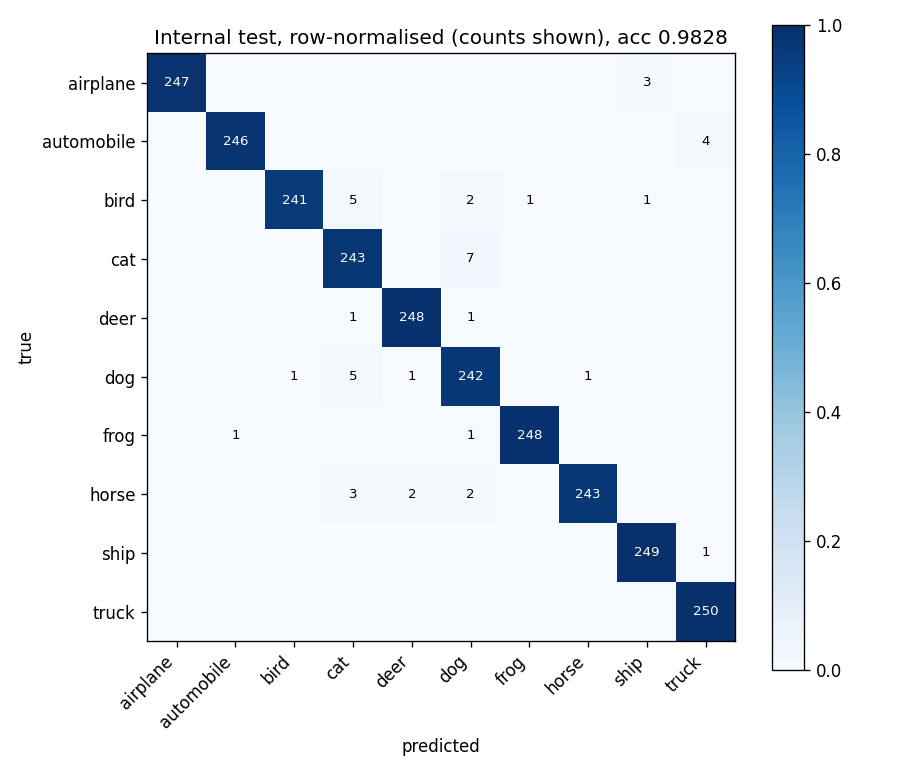

In [5]:
from IPython.display import Image, display
display(Image("../results/kd_sewrn_only_student_resnext29_slasd_400ep_v1_ft100_lr0.02/confusion_internal_test.png", width=520))